## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [24]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

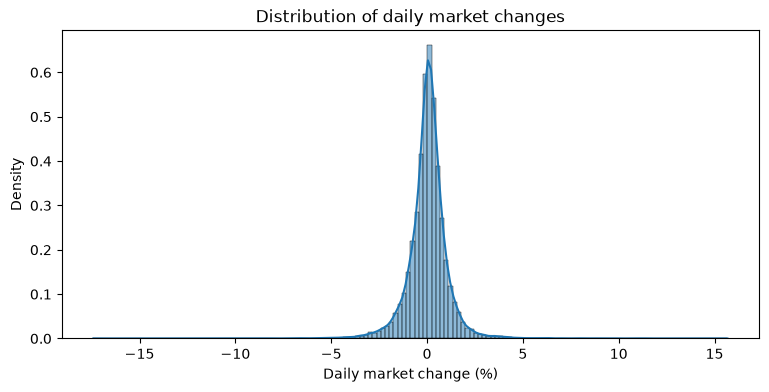

In [27]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

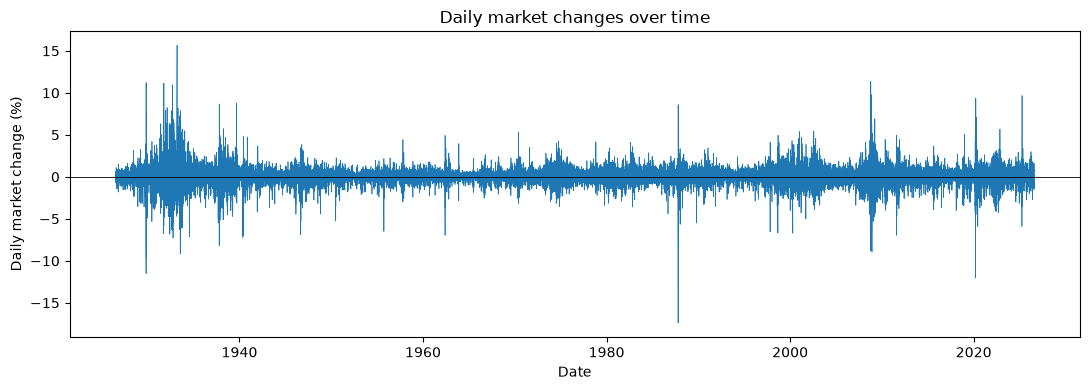

In [28]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [29]:


df['y_t'] = np.where(
    df['market_return_pct'] > 0,
    'Up',
    'Down (and flat)'
)
df['y_tp1'] = df['y_t'].shift(-1)

print(pd.crosstab(df['y_t'], df['y_tp1']))
print(df['y_t'].value_counts())


y_tp1            Down (and flat)    Up
y_t                                   
Down (and flat)             5909  5999
Up                          5999  8388
y_t
Up                 14388
Down (and flat)    11908
Name: count, dtype: int64


In [30]:
print((df['market_return_pct'] >0).value_counts())
print((df['market_return_pct'] <=0).value_counts())

market_return_pct
True     14388
False    11908
Name: count, dtype: int64
market_return_pct
False    14388
True     11908
Name: count, dtype: int64


- 

In [31]:
df['return_t'] = df['market_return_pct']

df['return_tp1'] = df['market_return_pct'].shift(-1)

df[['date', 'market_return_pct', 'y_t', 'y_tp1']].head(10)

,date,market_return_pct,y_t,y_tp1
0,1926-07-01,0.10,Up,Up
1,1926-07-02,0.46,Up,Up
2,1926-07-06,0.18,Up,Up
3,1926-07-07,0.10,Up,Up
4,1926-07-08,0.23,Up,Down (and flat)
5,1926-07-09,-0.70,Down (and flat),Up
6,1926-07-10,0.62,Up,Up
7,1926-07-12,0.05,Up,Up
8,1926-07-13,0.49,Up,Up
9,1926-07-14,0.05,Up,Down (and flat)


In [32]:
cond_pmf = pd.crosstab(
    df['y_t'],
    df['y_tp1'],
    normalize='index'

)
print(cond_pmf)

y_tp1            Down (and flat)        Up
y_t                                       
Down (and flat)         0.496221  0.503779
Up                      0.416974  0.583026


<Axes: xlabel='y_tp1', ylabel='y_t'>

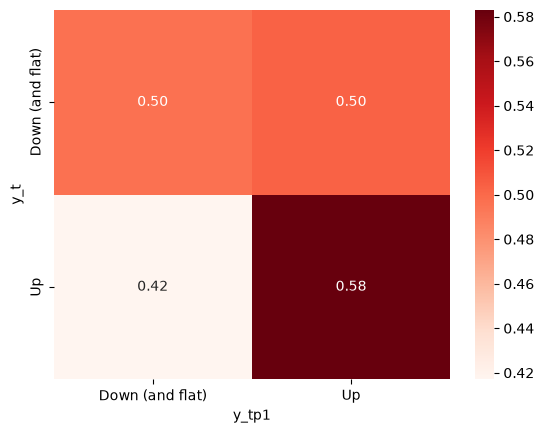

In [42]:
sns.heatmap(cond_pmf, annot=True, fmt='.2f', cmap='Reds')

- Up transitions are more likely that down transitions. It's more likely to transition to up day from up days than up days from down days.  Based on the conditional pmf, there is 58% probability that the stocks would go up after up days, whereas it's 50/50 when it's down or/and flat. 

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [46]:
df['market_return_bin'] = pd.cut(
    df['market_return_pct'], bins = [-float('inf'), -1, -0.1, 0.1, 1, float('inf')],
    labels = [
        'Large Loss',
        'Small loss',
        'Near zero',
        'Small gain',
        'Large gain'
    ], 
)
df['y_t'] = df['market_return_bin']
df['y_tp1'] = df['market_return_bin'].shift(-1)

In [48]:
tab= pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
tab

y_tp1,Large Loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large Loss,0.021335,0.027191,0.009051,0.027800,0.019547
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928


[Text(0.5, 1.0, 'Joint PMF')]

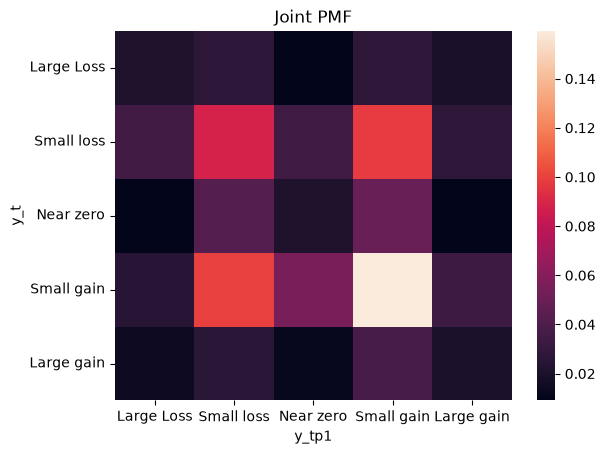

In [49]:
sns.heatmap(tab).set(title='Joint PMF')

In [44]:
market_bins = pd.cut(
    df['market_return_pct'],
    bins=[-float('inf'), -1, -0.1, 0.1, 1, float('inf')],
    labels=[
        'Large Loss',
        'Small loss',
        'Near zero',
        'Small gain',
        'Large gain'
    ],
    right=True
)
market_bins.value_counts().sort_index()

market_return_pct
Large Loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64

- Since 1926, small gains and small losses have been the most common market outcomes. Small gains occurred approximately 9785 days compared to 7452 for small losses. Small gains were the most frequent outcome overall, while large losses were surprisingly the least common.

In [36]:
pmf = market_bins.value_counts(normalize=True).sort_index()

print(pmf)

market_return_pct
Large Loss    0.104921
Small loss    0.283389
Near zero     0.130856
Small gain    0.372110
Large gain    0.108724
Name: proportion, dtype: float64


- Small gains are about 37.21%. 

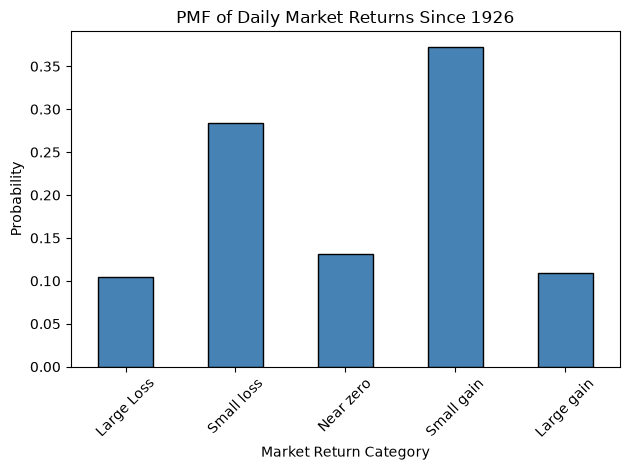

In [37]:
pmf.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('PMF of Daily Market Returns Since 1926')
plt.xlabel('Market Return Category')
plt.ylabel('Probability')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

 Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?

In [51]:
conditional_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
conditional_pmf

y_tp1,Large Loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large Loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


- The two most likely future states are `small gain` followed by `small gain`, with a joint probability mass function (PMF) of 42.84%. Two columns have a uniform PMF greater than 0.2, indicating relatively high probabilities. This suggests that the next state is fairly predictable, as `small gain` and `small loss` are the most frequently occurring outcomes following each state.

[Text(0.5, 1.0, 'Conditional PMF')]

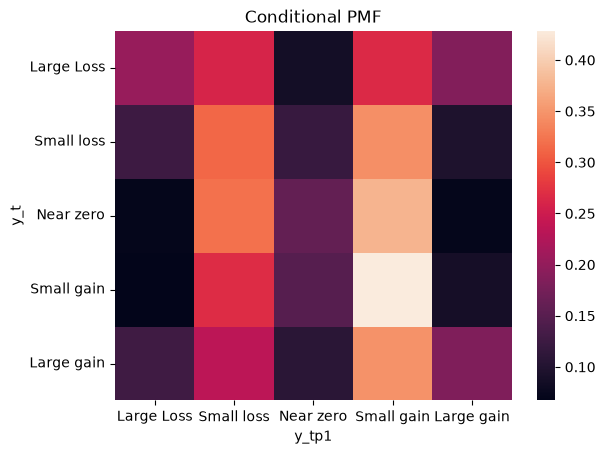

In [52]:
sns.heatmap(conditional_pmf).set(title='Conditional PMF')

**2** For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [54]:
df['market_tp1'] = df['market_return_pct'].shift(-1)
df.groupby('y_t', observed=False)['market_tp1'].describe()

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large Loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [62]:
df['y_t'] = pd.qcut(df['market_return_pct'], q=21, labels=False, duplicates='drop')
df['y_tp1'] = df['y_t'].shift(-1)
df[['market_return_pct', 'y_t', 'y_tp1']].head(10)

,market_return_pct,y_t,y_tp1
0,0.10,10,15.0
1,0.46,15,11.0
2,0.18,11,10.0
3,0.10,10,12.0
4,0.23,12,3.0
5,-0.70,3,16.0
6,0.62,16,10.0
7,0.05,10,15.0
8,0.49,15,10.0
9,0.05,10,4.0


In [65]:
joint_pmf = pd.crosstab(
    df['y_t'],
    df['y_tp1'],
    normalize=True
)

adjusted_pmf = joint_pmf - (1 / 21**2)
adjusted_pmf

y_tp1,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0
y_t,,,,,,,,,,,,,,,,,,,,,
0,0.004692,0.001383,0.000661,-0.000480,-0.000062,-0.000518,-0.000442,-0.001127,-0.000898,-0.000937,...,-0.001241,-0.000937,-0.000937,-0.001165,-0.000670,-0.001127,-0.000328,-0.000252,0.001345,0.004616
1,0.002600,0.001117,0.000927,-0.000062,0.000052,-0.000290,-0.000062,-0.000594,-0.000822,0.000052,...,-0.000708,-0.000937,-0.000746,-0.000556,-0.000670,-0.000442,-0.000442,0.000623,0.000242,0.001383
2,0.001383,0.001497,0.001459,0.001535,-0.000024,-0.000404,-0.000138,-0.000442,-0.000784,-0.000214,...,-0.000290,0.000090,-0.000024,-0.000632,-0.000898,-0.000214,-0.000442,0.000052,0.000242,0.000395
3,0.000547,0.001421,0.000813,0.000509,0.000433,0.000204,0.000090,-0.000708,-0.000138,0.000128,...,-0.000480,-0.000328,-0.000746,0.000014,-0.000138,0.000014,-0.000480,0.000166,0.000280,-0.000176
4,0.000052,0.000433,0.000623,0.000318,-0.000138,0.000280,0.000356,-0.000100,0.000052,-0.000442,...,-0.000214,-0.000404,-0.000518,0.000471,-0.000100,-0.000328,0.000395,-0.000632,0.000014,-0.000404
5,-0.000214,0.000585,0.000242,0.000623,0.000471,-0.000062,0.000014,0.000166,-0.000328,-0.000138,...,-0.000404,-0.000062,-0.000176,-0.000328,-0.000214,0.000318,0.000356,-0.000708,-0.000328,-0.000328
6,0.000128,0.000547,0.001079,0.000927,0.000547,0.000547,-0.000062,-0.000024,0.000166,0.000204,...,-0.000328,0.000318,0.000927,0.000242,-0.000138,0.000242,-0.000328,-0.000518,0.000128,-0.000594
7,-0.000746,0.000090,0.000166,0.000889,-0.000100,0.000090,0.000509,0.000166,-0.000366,0.000014,...,0.000090,0.000204,-0.000404,-0.000062,-0.000062,-0.000746,-0.000328,-0.000404,-0.000290,-0.001089
8,-0.000937,-0.000252,0.000166,0.000166,0.000242,0.000204,0.000052,0.000204,0.000090,0.000471,...,0.000204,0.000166,-0.000062,0.000242,0.000090,-0.000366,-0.000138,-0.000480,-0.000822,-0.000746


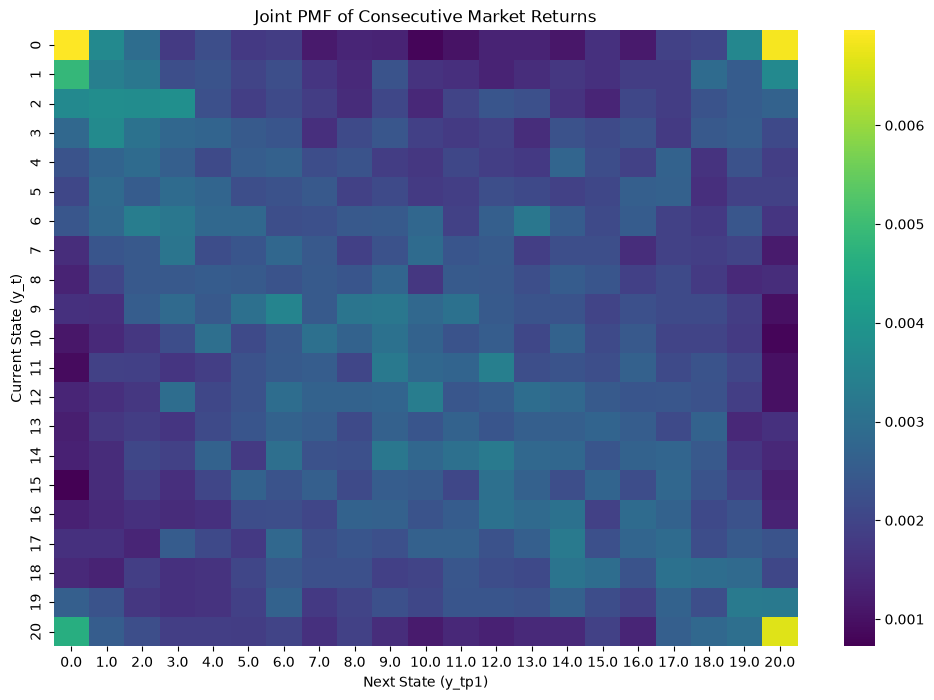

In [67]:
plt.figure(figsize=(12, 8))
sns.heatmap(joint_pmf, cmap='viridis', annot=False)
plt.title('Joint PMF of Consecutive Market Returns')
plt.xlabel('Next State (y_tp1)')
plt.ylabel('Current State (y_t)')
plt.show()


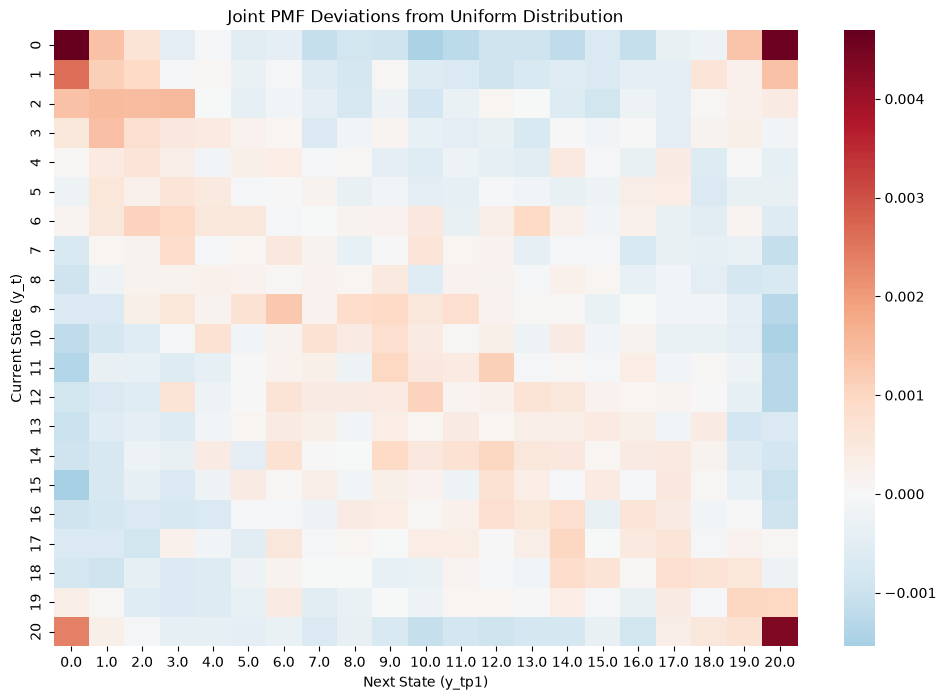

In [70]:
plt.figure(figsize=(12, 8))
sns.heatmap(adjusted_pmf, cmap='RdBu_r', center=0, annot=False)
plt.title('Joint PMF Deviations from Uniform Distribution')
plt.xlabel('Next State (y_tp1)')
plt.ylabel('Current State (y_t)')
plt.show()

In [72]:
conditional_pmf = pd.crosstab(
    df['y_t'],
    df['y_tp1'],
    normalize='index'
)
conditional_pmf

y_tp1,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0
y_t,,,,,,,,,,,,,,,,,,,,,
0,0.145817,0.076494,0.061355,0.037450,0.046215,0.036653,0.038247,0.023904,0.028685,0.027888,...,0.021514,0.027888,0.027888,0.023108,0.033466,0.023904,0.040637,0.042231,0.075697,0.144223
1,0.102155,0.071030,0.067039,0.046289,0.048683,0.041500,0.046289,0.035116,0.030327,0.048683,...,0.032721,0.027933,0.031923,0.035914,0.033520,0.038308,0.038308,0.060654,0.052674,0.076616
2,0.074650,0.076983,0.076205,0.077760,0.045879,0.038103,0.043546,0.037325,0.030327,0.041991,...,0.040435,0.048212,0.045879,0.033437,0.027994,0.041991,0.037325,0.047434,0.051322,0.054432
3,0.057813,0.075781,0.063281,0.057031,0.055469,0.050781,0.048438,0.032031,0.043750,0.049219,...,0.036719,0.039844,0.031250,0.046875,0.043750,0.046875,0.036719,0.050000,0.052344,0.042969
4,0.049593,0.057724,0.061789,0.055285,0.045528,0.054472,0.056098,0.046341,0.049593,0.039024,...,0.043902,0.039837,0.037398,0.058537,0.046341,0.041463,0.056911,0.034959,0.048780,0.039837
5,0.044046,0.061175,0.053834,0.061990,0.058728,0.047308,0.048940,0.052202,0.041599,0.045677,...,0.039967,0.047308,0.044861,0.041599,0.044046,0.055465,0.056281,0.033442,0.041599,0.041599
6,0.045952,0.053975,0.064187,0.061269,0.053975,0.053975,0.042305,0.043034,0.046681,0.047411,...,0.037199,0.049599,0.061269,0.048140,0.040846,0.048140,0.037199,0.033552,0.045952,0.032093
7,0.033167,0.051410,0.053068,0.068823,0.047264,0.051410,0.060531,0.053068,0.041459,0.049751,...,0.051410,0.053897,0.040630,0.048093,0.048093,0.033167,0.042289,0.040630,0.043118,0.025705
8,0.029215,0.044240,0.053422,0.053422,0.055092,0.054257,0.050918,0.054257,0.051753,0.060100,...,0.054257,0.053422,0.048414,0.055092,0.051753,0.041736,0.046745,0.039232,0.031720,0.033389


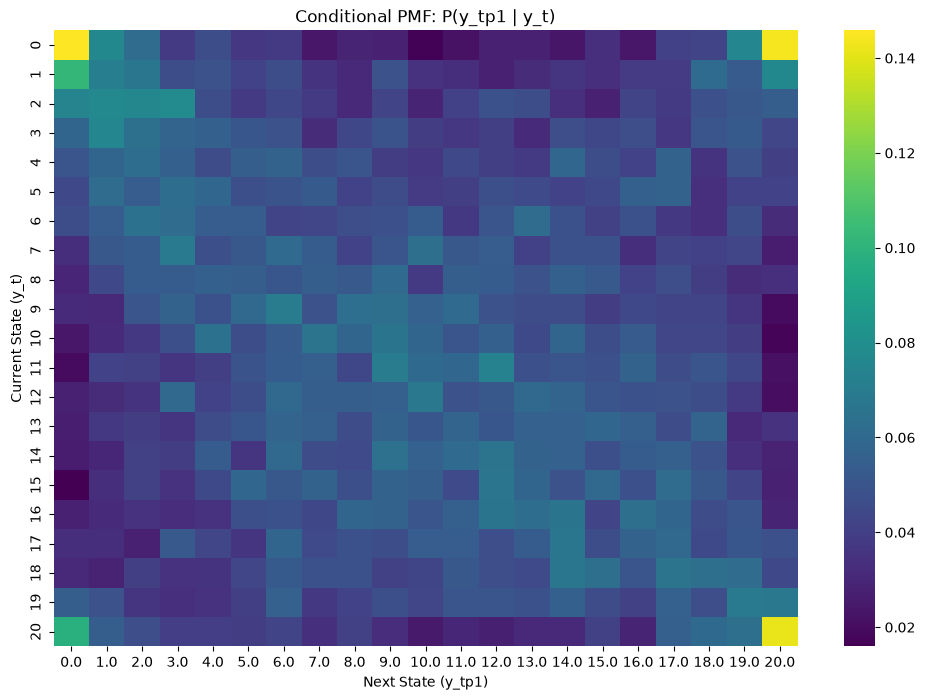

In [73]:
plt.figure(figsize=(12, 8))
sns.heatmap(conditional_pmf, cmap='viridis', annot=False)
plt.title('Conditional PMF: P(y_tp1 | y_t)')
plt.xlabel('Next State (y_tp1)')
plt.ylabel('Current State (y_t)')
plt.show()

In [75]:
adjusted_conditional_pmf = conditional_pmf - (1 / 21)
adjusted_conditional_pmf

y_tp1,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0
y_t,,,,,,,,,,,,,,,,,,,,,
0,0.098198,0.028875,0.013736,-0.010169,-0.001404,-0.010966,-0.009372,-0.023715,-0.018934,-0.019731,...,-0.026105,-0.019731,-0.019731,-0.024511,-0.014153,-0.023715,-0.006982,-0.005388,0.028078,0.096604
1,0.054536,0.023410,0.019420,-0.001330,0.001064,-0.006119,-0.001330,-0.012503,-0.017292,0.001064,...,-0.014898,-0.019686,-0.015696,-0.011705,-0.014099,-0.009311,-0.009311,0.013035,0.005055,0.028997
2,0.027031,0.029364,0.028586,0.030141,-0.001740,-0.009516,-0.004073,-0.010294,-0.017292,-0.005628,...,-0.007184,0.000592,-0.001740,-0.014182,-0.019625,-0.005628,-0.010294,-0.000185,0.003703,0.006813
3,0.010193,0.028162,0.015662,0.009412,0.007850,0.003162,0.000818,-0.015588,-0.003869,0.001600,...,-0.010900,-0.007775,-0.016369,-0.000744,-0.003869,-0.000744,-0.010900,0.002381,0.004725,-0.004650
4,0.001974,0.010105,0.014170,0.007666,-0.002091,0.006852,0.008479,-0.001278,0.001974,-0.008595,...,-0.003717,-0.007782,-0.010221,0.010918,-0.001278,-0.006156,0.009292,-0.012660,0.001161,-0.007782
5,-0.003573,0.013556,0.006215,0.014371,0.011109,-0.000311,0.001321,0.004583,-0.006020,-0.001942,...,-0.007652,-0.000311,-0.002758,-0.006020,-0.003573,0.007846,0.008662,-0.014177,-0.006020,-0.006020
6,-0.001667,0.006356,0.016568,0.013650,0.006356,0.006356,-0.005314,-0.004585,-0.000938,-0.000208,...,-0.010420,0.001980,0.013650,0.000521,-0.006773,0.000521,-0.010420,-0.014067,-0.001667,-0.015526
7,-0.014452,0.003791,0.005449,0.021204,-0.000355,0.003791,0.012912,0.005449,-0.006160,0.002132,...,0.003791,0.006278,-0.006989,0.000474,0.000474,-0.014452,-0.005330,-0.006989,-0.004501,-0.021914
8,-0.018404,-0.003379,0.005803,0.005803,0.007473,0.006638,0.003299,0.006638,0.004134,0.012481,...,0.006638,0.005803,0.000795,0.007473,0.004134,-0.005883,-0.000874,-0.008387,-0.015900,-0.014230


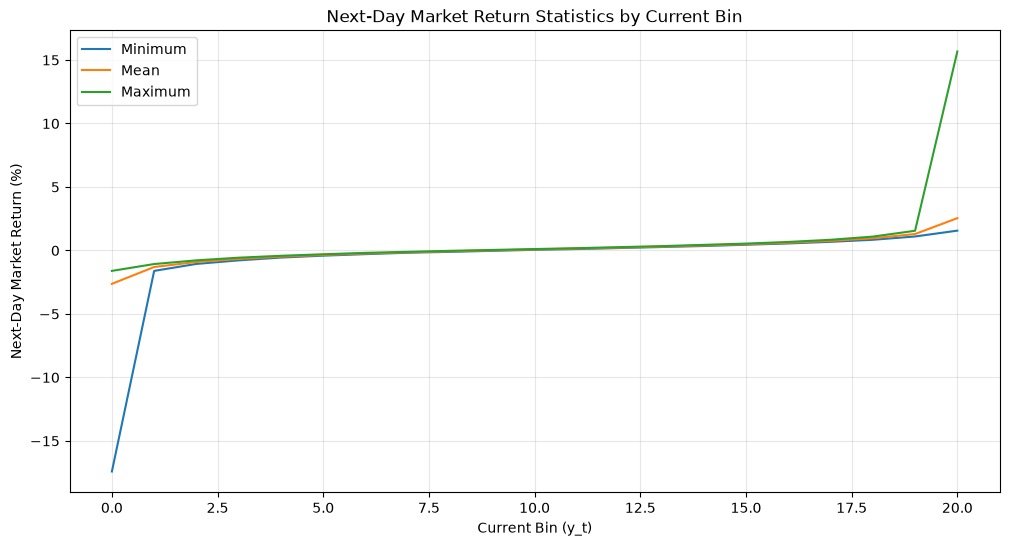

In [ ]:
stats = df.groupby('y_t')['market_return_pct'].agg(
    ['min', 'mean', 'max']
)


plt.figure(figsize=(12, 6))

sns.lineplot(data=stats, x=stats.index, y='min', label='Minimum')
sns.lineplot(data=stats, x=stats.index, y='mean', label='Mean')
sns.lineplot(data=stats, x=stats.index, y='max', label='Maximum')
plt.title('Next-Day Market Return Statistics by Current Bin')
plt.xlabel('Current Bin (y_t)')
plt.ylabel('Next-Day Market Return (%)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

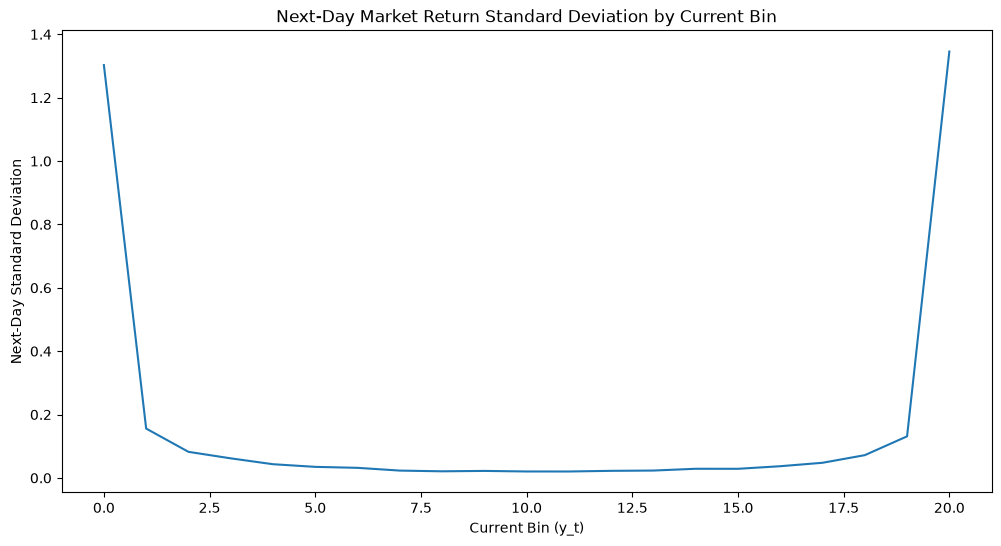

In [87]:

next_day_std = df.groupby('y_t')['market_return_pct'].std()


plt.figure(figsize=(12, 6))

sns.lineplot(x=next_day_std.index, y=next_day_std.values)

plt.title('Next-Day Market Return Standard Deviation by Current Bin')
plt.xlabel('Current Bin (y_t)')
plt.ylabel('Next-Day Standard Deviation')
plt.show()

overall, predicting the market is relatively difficult. Although the conditional PMF may reveal some patterns in transitions between market states, these patterns do not necessarily translate into reliable predictions. The next day's returns can vary significantly, as reflected by the minimum, maximum, and standard deviation plots.